In [2]:
import numpy as np
from matplotlib import pyplot as plt

from functions import featureNormalize, computeCostMulti, gradientDescentMulti, normalEqn

In [3]:
data = np.loadtxt('ex1data2.txt', delimiter=',')
X = data[:, :2]
y = data[:, 2]



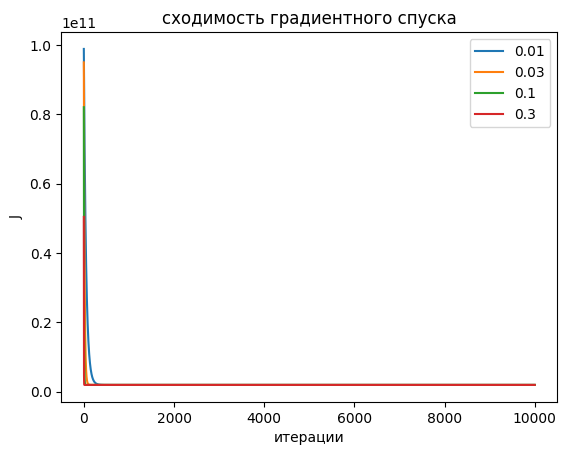

[134900.83565041  -5818.08803553 423875.09178744]


In [4]:
X_norm = featureNormalize(X)
num_iters = 10000
J_histories = []
alphas = [0.01, 0.03, 0.1, 0.3]
thetas = {}

for alpha in alphas:
    theta = np.zeros(3)
    J_history = []
    for _ in range(num_iters):
        theta = gradientDescentMulti(theta, X_norm, y, alpha)
        J_history.append(computeCostMulti(X_norm, theta, y))
    J_histories.append([alpha, J_history])
    thetas[alpha] = theta

for J_history in J_histories:
    plt.plot(range(num_iters), J_history[1])
    plt.xlabel('итерации')
    plt.ylabel('J')
    plt.title('сходимость градиентного спуска')
    plt.legend(alphas)
plt.show()
print(thetas[0.03])




In [5]:
theta_analitical = normalEqn(X, y)
print(theta_analitical)

[   127.99058603  -4489.19890422 106215.95288628]


In [6]:
speed = float(input("Скорость оборота: "))
gears = float(input("Количество передач: "))
x_new_raw = np.array([speed, gears])
mu = X.mean(axis=0)
sigma = X.std(axis=0)
x_new_norm = (x_new_raw - mu) / sigma
pred_gd = np.dot(np.append(x_new_norm, 1), thetas[0.03])
pred_ne = np.dot(np.append(x_new_raw, 1), theta_analitical)
print(pred_gd, pred_ne)


472230.915360611 472230.9153606175


In [14]:
print(X.mean(axis=0))
print(X.std(axis=0))

[2588.47342995    3.03864734]
[1053.99029596    1.29601921]


In [15]:
np.dot([(2000 - 2588.47342995) / 1053.99029596, (3 - 3.03864734) / 1.29601921, 1], thetas[0.03])

np.float64(348729.52822166565)

In [13]:
np.dot([2000, 3, 1], theta_analitical)

np.float64(348729.52823443187)